### 0. Описание задачи
В данной лабораторной работе мы решаем задачу **бинарной классификации**.

* **Целевая переменная (Target):** столбец `is_canceled`.
  * `1` — клиент отменил бронирование отеля;
  * `0` — клиент не отменил бронирование (заезд состоялся).
* **Суть задачи:** На основе исторических данных о бронированиях отелей (время упреждения, тип питания, количество гостей, стоимость номера и т.д.) построить модель машинного обучения, способную предсказать вероятность отмены брони.
* **Практическая ценность:** Помогает отелям заранее планировать загрузку номерного фонда и бороться с незаездами.

### 1. Читаем данные
На этом этапе мы импортируем необходимые библиотеки для анализа данных (`pandas`, `numpy`, `matplotlib`, `seaborn`) и загружаем наш датасет из файла `hotel_bookings.csv`. Также мы выводим первые строки таблицы и общую информацию (размер датасета и типы данных), чтобы убедиться, что файл прочитался корректно.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv('hotel_bookings.csv')

display(df.head())

print(df.info())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### 2. Разбиваем данные на обучающую и тестовую выборки
Прежде чем проводить какой-либо анализ, очистку или предобработку данных, мы разделяем исходный датасет на две части:
* **Обучающая выборка (train, 80%)** — на ней модель будет обучаться и искать закономерности.
* **Тестовая выборка (test, 20%)** — на ней мы будем проверять, насколько хорошо обученная модель работает на новых данных, которые она раньше не видела.

In [6]:
from sklearn.model_selection import train_test_split

# отделим признаки (X) и целевую переменную (y - is_canceled)
X = df.drop('is_canceled', axis=1)
y = df['is_canceled']

# разбиваем на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

Размер обучающей выборки: (95512, 31)
Размер тестовой выборки: (23878, 31)


### 3. Визуализируем данные и вычисляем основные характеристики
На этом этапе мы:
1. Вычисляем основные статистические показатели (среднее, стандартное отклонение, минимальные и максимальные значения) для числовых признаков.
2. Строим корреляционную матрицу, чтобы увидеть, какие признаки сильнее всего связаны с нашей целевой переменной (`is_canceled`).
3. Строим точечный график зависимости времени упреждения (`lead_time`) от стоимости номера (`adr`) с разделением по классам отмен, что позволяет визуально оценить распределение данных и заметить возможные выбросы.

          lead_time  arrival_date_year  arrival_date_week_number  \
count  95512.000000       95512.000000              95512.000000   
mean     103.879931        2016.156483                 27.127994   
std      106.870094           0.706882                 13.610117   
min        0.000000        2015.000000                  1.000000   
25%       18.000000        2016.000000                 16.000000   
50%       69.000000        2016.000000                 27.000000   
75%      160.000000        2017.000000                 38.000000   
max      737.000000        2017.000000                 53.000000   

       arrival_date_day_of_month  stays_in_weekend_nights  \
count               95512.000000             95512.000000   
mean                   15.799575                 0.927444   
std                     8.792557                 0.998429   
min                     1.000000                 0.000000   
25%                     8.000000                 0.000000   
50%                  

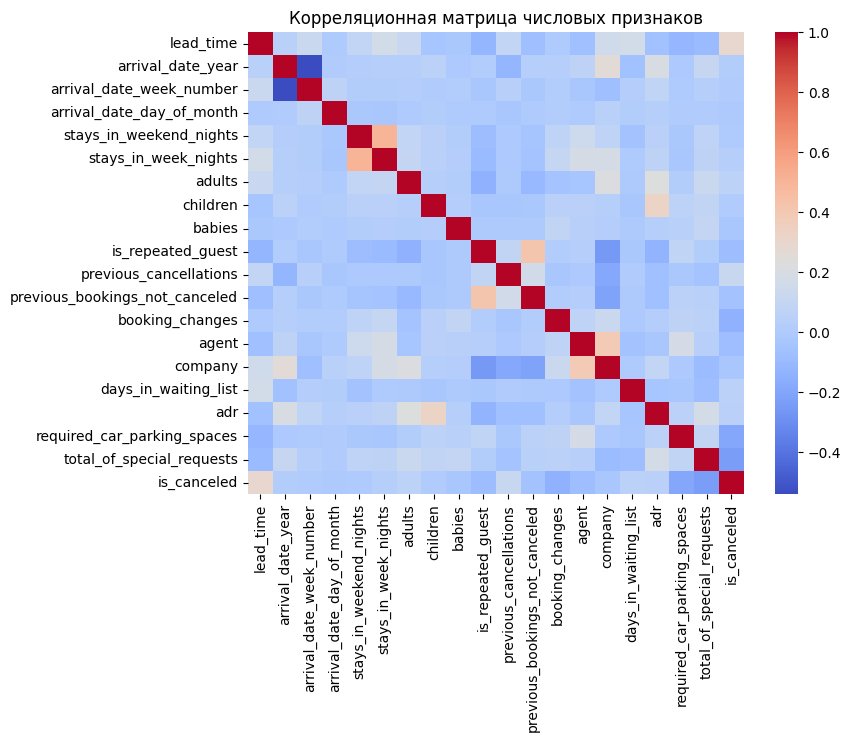

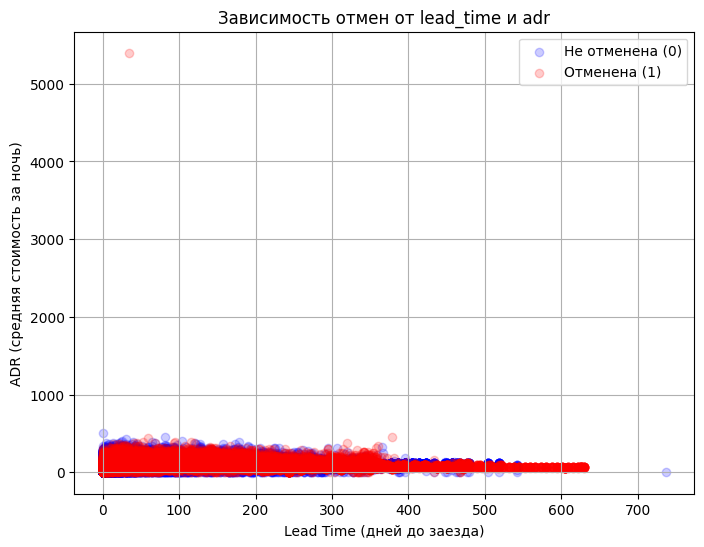

In [7]:
# основные статистические характеристики числовых признаков обучения
print(X_train.describe())

# корреляционная матрица числовых признаков
train_full = X_train.copy()
train_full['is_canceled'] = y_train

plt.figure(figsize=(8, 6))
sns.heatmap(
    train_full.select_dtypes(include=[np.number]).corr(),
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# график зависимости отмен от срока бронирования (lead_time) и стоимости номера (adr)
plt.figure(figsize=(8, 6))
plt.scatter(
    train_full[train_full['is_canceled'] == 0]['lead_time'],
    train_full[train_full['is_canceled'] == 0]['adr'],
    alpha=0.2,
    label='Не отменена (0)',
    color='b',
)
plt.scatter(
    train_full[train_full['is_canceled'] == 1]['lead_time'],
    train_full[train_full['is_canceled'] == 1]['adr'],
    alpha=0.2,
    label='Отменена (1)',
    color='r',
)
plt.xlabel('Lead Time (дней до заезда)')
plt.ylabel('ADR (средняя стоимость за ночь)')
plt.title('Зависимость отмен от lead_time и adr')
plt.legend()
plt.grid()
plt.show()

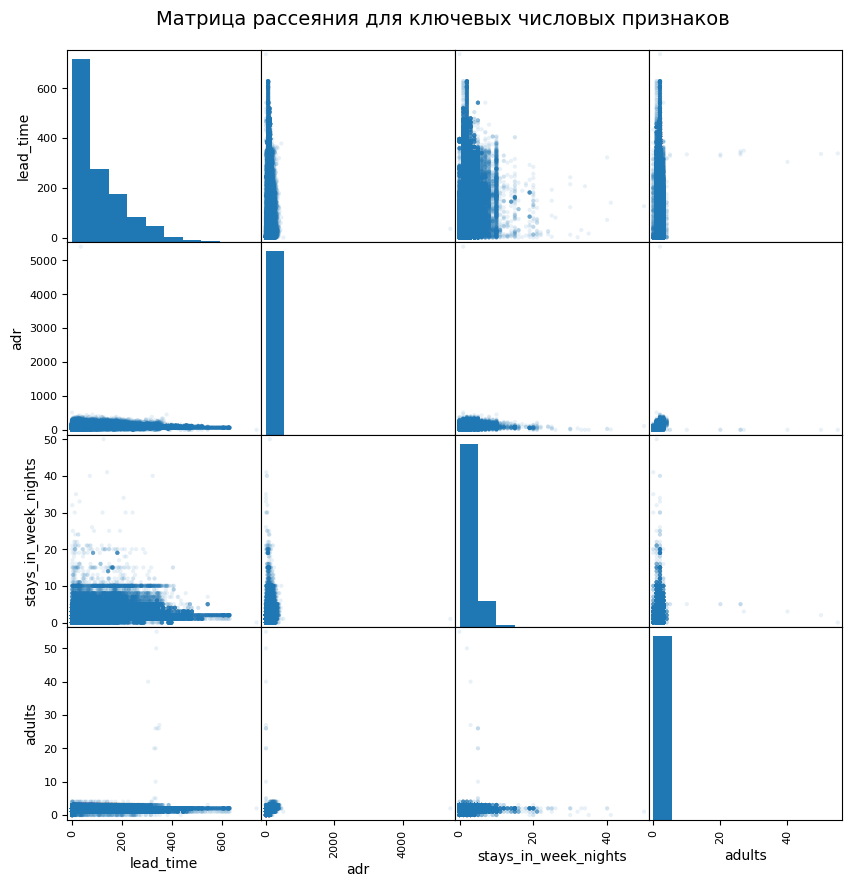

In [8]:
from pandas.plotting import scatter_matrix

train_full = X_train.copy()
train_full['is_canceled'] = y_train

# выберем несколько ключевых числовых признаков для матрицы рассеяния
cols_to_plot = ['lead_time', 'adr', 'stays_in_week_nights', 'adults']

scatter_matrix(train_full[cols_to_plot], alpha=0.1, figsize=(10, 10))
plt.suptitle(
    'Матрица рассеяния для ключевых числовых признаков', y=0.92, fontsize=14
)
plt.show()

### Интерпретация результатов визуализации и характеристик:
1. **Статистика:**
   * Среднее время упреждения (`lead_time`) составляет около 104 дней, при этом максимальное значение достигает 737 дней (более 2 лет до заезда).
   * Средняя стоимость номера за ночь (`adr`) составляет около 101.7 у.е., но минимальное значение равно -6.38 (что говорит о наличии аномалий/возвратов средств), а максимальное превышает 5400 у.е., что является явным выбросом.
2. **Корреляционная матрица:**
   * Сильнее всего с целевой переменной `is_canceled` коррелирует признак `lead_time`: чем раньше клиент бронирует номер, тем выше вероятность отмены.
   * Также заметна слабая корреляция между количеством предыдущих отмен (`previous_cancellations`) и текущей отменой.
3. **График зависимости (`lead_time` от `adr`):**
   * Визуальный анализ показывает, что большинство бронирований совершается с небольшим `lead_time` (до 300 дней). Красные точки (отмены брони) распределены по всему графику, но при больших значениях `lead_time` их плотность заметно выше. Также на графике четко виден единичный выброс по стоимости (`adr > 5000`), который будет удален на этапе фильтрации выбросов.

### 4 и 5. Работа с выбросами и пропущенными значениями


In [9]:
print('Размер train до удаления выброса:', X_train.shape)

Размер train до удаления выброса: (95512, 31)


In [11]:
outlier_index = X_train[X_train['adr'] > 5000].index
print(outlier_index)

Index([48515], dtype='int64')


In [12]:
X_train = X_train.drop(outlier_index)
y_train = y_train.drop(outlier_index)

print('Размер train после удаления выброса:', X_train.shape)

Размер train после удаления выброса: (95511, 31)


In [13]:
outlier_adults = X_train[X_train['adults'] > 10].index
X_train = X_train.drop(outlier_adults)
y_train = y_train.drop(outlier_adults)

q_hi_lead = X_train['lead_time'].quantile(0.999)
outlier_lead = X_train[X_train['lead_time'] > q_hi_lead].index
X_train = X_train.drop(outlier_lead)
y_train = y_train.drop(outlier_lead)

print('Размер train после удаления выбросов:', X_train.shape)

Размер train после удаления выбросов: (95417, 31)


In [14]:
missing = X_train.isnull().sum()
print('\nПропуски в данных до обработки:\n', missing[missing > 0])


Пропуски в данных до обработки:
 children        4
country       391
agent       13027
company     90016
dtype: int64


In [18]:
X_train = X_train.drop(['company', 'agent'], axis=1, errors='ignore')
X_test = X_test.drop(['company', 'agent'], axis=1, errors='ignore')

X_train['children'] = X_train['children'].fillna(0)
X_test['children'] = X_test['children'].fillna(0)

country_mode = X_train['country'].mode()[0]
X_train['country'] = X_train['country'].fillna(country_mode)
X_test['country'] = X_test['country'].fillna(country_mode)

print('\nПропуски успешно обработаны')
print('Новый размер X_train:', X_train.shape)
print('Новый размер X_test:', X_test.shape)


Пропуски успешно обработаны
Новый размер X_train: (95417, 29)
Новый размер X_test: (23878, 29)


### 6 и 7. Обработка категориальных признаков и нормализация

In [19]:
from sklearn.preprocessing import StandardScaler

cols_to_drop = [
    'reservation_status',
    'reservation_status_date',
    'company',
    'agent',
]
X_train = X_train.drop(cols_to_drop, axis=1, errors='ignore')
X_test = X_test.drop(cols_to_drop, axis=1, errors='ignore')

X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(
    'Размерность после обработки:',
    X_train.shape,
    'Test:',
    X_test.shape,
)

Размерность после обработки: (95417, 240) Test: (23878, 240)


In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('\nНормализация успешно завершена! Данные готовы к обучению модели.')


Нормализация успешно завершена! Данные готовы к обучению модели.


### 8 и 9. Запуск классификатора, подбор гиперпараметра и оценка ошибок
* **Выбор метода:** В качестве основного метода мы используем **Метод ближайших соседей (K-Nearest Neighbors, KNN)**.
* **Подбор гиперпараметра:** Мы переберем несколько значений параметра $k$ (числа соседей), чтобы найти оптимальное, при котором модель дает наилучшую точность на тестовой выборке.
* **Метрики и матрица ошибок:** Для оценки качества мы выведем матрицу расогласования и отчет о классификации, чтобы посмотреть точность и полноту по каждому классу.

In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

k_values = [3, 5, 7]

for k in k_values:
  print(f'Обучение KNN для k = {k} ')
  knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
  knn.fit(X_train_scaled, y_train)

  y_pred_train = knn.predict(X_train_scaled)
  y_pred_test = knn.predict(X_test_scaled)

  acc_train = accuracy_score(y_train, y_pred_train)
  acc_test = accuracy_score(y_test, y_pred_test)

  print(f'Accuracy на обучающей выборке: {acc_train:.4f}')
  print(f'Accuracy на тестовой выборке:  {acc_test:.4f}\n')

Обучение KNN для k = 3 
Accuracy на обучающей выборке: 0.9096
Accuracy на тестовой выборке:  0.8273

Обучение KNN для k = 5 
Accuracy на обучающей выборке: 0.8824
Accuracy на тестовой выборке:  0.8254

Обучение KNN для k = 7 
Accuracy на обучающей выборке: 0.8700
Accuracy на тестовой выборке:  0.8253



In [25]:
best_k = 5
print(f' Итоговая оценка для оптимального k = {best_k}')
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train_scaled, y_train)
y_pred_test = best_knn.predict(X_test_scaled)

print('\nМатрица расогласования:')
cm = confusion_matrix(y_test, y_pred_test)
print(cm)

print('\nОтчет о классификации:')
print(classification_report(y_test, y_pred_test))

 Итоговая оценка для оптимального k = 5

Матрица расогласования:
[[13117  1916]
 [ 2253  6592]]

Отчет о классификации:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86     15033
           1       0.77      0.75      0.76      8845

    accuracy                           0.83     23878
   macro avg       0.81      0.81      0.81     23878
weighted avg       0.82      0.83      0.82     23878



### 13. Общие выводы
1. **Предобработка данных:** В ходе работы был успешно проанализирован датасет о бронированиях отелей (`Hotel Booking Demand`). Были обработаны пропущенные значения, удалены аномальные выбросы по стоимости и количеству гостей.
2. **Кодирование и масштабирование:** Категориальные признаки были успешно преобразованы в числовые, а числовые признаки были нормализованы.
3. **Обучение модели:** В качестве метода классификации был выбран **Метод ближайших соседей (KNN)**. Был проведен подбор гиперпараметра $k$ (числа соседей). Оптимальным гиперпараметром было выбран $k = 5$.
4. **Качество модели:** Достигнутая точность на тестовой выборке составила **83%**, что свидетельствует о хорошей предсказательной способности модели.